# Filter cost playground

Interactive front end to `filtercost.py`. Change the parameters in each section and re-run it.

1. Pick a chain and look at the two knobs (gap via dimerisation, overlap via staggered Rz)
2. Measure the cheapest filter at one (gap, overlap) point, with repeat-until-success and amplitude amplification
3. See what that filter does to the spectrum, and check it gate by gate
4. Run a small (gap, overlap) map and fit the exponents
5. Load the saved N = 8–16 results

Small N (8–12) runs in seconds. N = 14 takes minutes per point, N = 16 about 10 minutes.

In [1]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
import filtercost as fc

## 1. The chain and the two knobs

`J2` and `N` set the chain. The gap knob is the dimerisation δ: J1 bonds become J1(1 ± δ).
δ < 0 closes the gap (weak end bonds, nearly free edge spins), δ > 0 opens it towards isolated dimers.

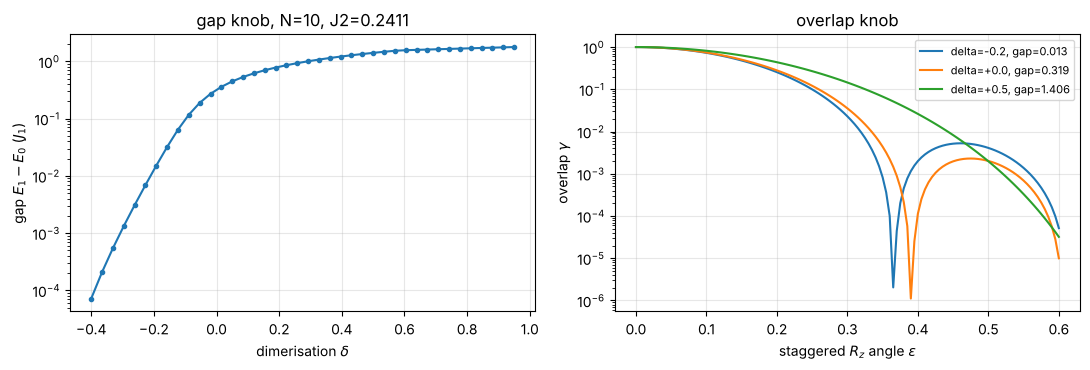

In [2]:
N, J1, J2 = 10, 1.0, 0.2411

deltas = np.linspace(-0.4, 0.95, 40)
gaps = [fc.Chain(N, d, J1, J2).gap for d in deltas]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogy(deltas, gaps, "o-", ms=3)
ax[0].set(xlabel=r"dimerisation $\delta$", ylabel=r"gap $E_1-E_0$ ($J_1$)", title=f"gap knob, N={N}, J2={J2}")
for d in (-0.2, 0.0, 0.5):
    ch = fc.Chain(N, d, J1, J2)
    es = np.linspace(0, 0.6, 121)
    ax[1].semilogy(es, [ch.overlap(e) for e in es], label=f"delta={d:+.1f}, gap={ch.gap:.3f}")
ax[1].set(xlabel=r"staggered $R_z$ angle $\epsilon$", ylabel=r"overlap $\gamma$", title="overlap knob")
for a in ax: a.grid(alpha=0.3)
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## 2. Measured cost at one point

Set the target gap, the overlaps and the infidelity targets. `measure_point` returns, for each overlap, eps and
protocol, the cheapest dyadic filter (K ladder rungs, r repetitions, n Strang steps per τ) whose simulated
1 − F ≤ eps and which still passes with finer Trotter steps.

In [3]:
GAP     = 0.1                       # physical gap (J1)
GAMMAS  = [0.01, 0.1, 0.5, 0.9]     # target overlaps
EPS     = [1e-2, 1e-3]              # target infidelities

delta = fc.delta_for_gap(N, GAP, J1=J1, J2=J2)
ch = fc.Chain(N, delta, J1, J2)
print(f"N={N}, delta={delta:+.4f}: gap {ch.gap:.4f}, bandwidth W {ch.W:.3f}, scaled gap {ch.gap_s:.5f}")

t0 = time.time()
rows, eps_knob = fc.measure_point(ch, GAMMAS, EPS)
print(f"measured in {time.time() - t0:.1f} s\n")
print(f"{'gamma':>6} {'eps':>6} {'prot':>4} {'K':>3} {'r':>3} {'n':>3} {'CNOT/attempt':>13} {'p':>7} {'1-F':>9} {'CNOT/success':>13}")
for g, row in zip(GAMMAS, rows):
    for e in EPS:
        for pr in fc.PROTOCOLS:
            b = row[e][pr]
            print(f"{g:6.3g} {e:6.0e} {pr:>4} {b['K']:3d} {b['r']:3d} {b['n']:3d} {b['cnot']:13,d} {b['p']:7.4f} "
                  f"{b['infid']:9.2e} {b['cost']:13,.0f}")

N=10, delta=-0.0981: gap 0.1000, bandwidth W 6.475, scaled gap 0.01544


measured in 0.5 s

 gamma    eps prot   K   r   n  CNOT/attempt       p       1-F  CNOT/success
  0.01  1e-02  rus   6   2   2        48,456  0.0097  2.13e-04     4,982,261
  0.01  1e-02   aa   6   2   2        48,456  0.0097  2.13e-04       732,641
  0.01  1e-03  rus   6   2   2        48,456  0.0097  2.13e-04     4,982,261
  0.01  1e-03   aa   6   2   2        48,456  0.0097  2.13e-04       732,641
   0.1  1e-02  rus   6   1   3        36,324  0.1000  2.72e-03       363,131
   0.1  1e-02   aa   6   2   1        24,264  0.0515  9.22e-03       170,023
   0.1  1e-03  rus   6   2   2        48,456  0.0962  5.00e-05       503,527
   0.1  1e-03   aa   6   2   2        48,456  0.0962  5.00e-05       242,290
   0.5  1e-02  rus   6   1   2        24,228  0.4907  1.59e-03        49,375
   0.5  1e-02   aa   6   1   2        24,228  0.4907  1.59e-03        49,375
   0.5  1e-03  rus   6   1   3        36,324  0.4983  3.12e-04        72,903
   0.5  1e-03   aa   6   1   3        36,324  0.4983  3.1

## 3. What the chosen filter does

The ideal (untrotterised) dyadic filter is F(E) = Π_k cos(τ 2^k E)^r on the scaled spectrum E ∈ [0, 1].
The plot shows |F(E)|² over the exact eigenvalues, against the trial's weight on each eigenstate.
Then the same filter is run gate by gate (Strang steps on the state vector) to check the measured numbers.

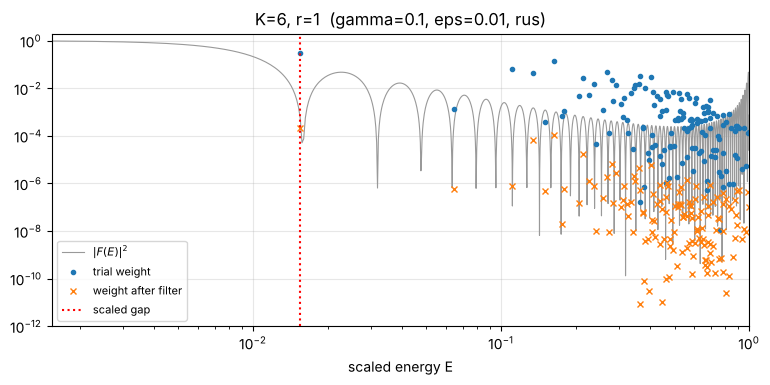

gate by gate:  p = 0.100030  1-F = 2.717e-03
measured:      p = 0.100030  1-F = 2.717e-03


In [4]:
GAMMA_PICK, EPS_PICK, PROT = 0.1, 1e-2, "rus"

b = rows[GAMMAS.index(GAMMA_PICK)][EPS_PICK][PROT]
H = ch.hamiltonian().toarray()
w, V = np.linalg.eigh(H)
E = (w - ch.E0) / ch.W
psi = ch.trial(eps_knob[GAMMAS.index(GAMMA_PICK)])
weight = np.abs(V.T @ psi) ** 2
tau = np.pi / (1 + ch.gap_s)
F = np.prod([np.cos(tau * 2 ** k * E) for k in range(b["K"])], axis=0) ** b["r"]
Egrid = np.linspace(0, 1, 4000)
Fgrid = np.prod([np.cos(tau * 2 ** k * Egrid) for k in range(b["K"])], axis=0) ** b["r"]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogy(Egrid, Fgrid ** 2 + 1e-30, color="0.6", lw=0.8, label=r"$|F(E)|^2$")
ax.semilogy(E, weight + 1e-30, "o", ms=3, label="trial weight")
ax.semilogy(E, weight * F ** 2 + 1e-30, "x", ms=4, label="weight after filter")
ax.axvline(ch.gap_s, color="r", ls=":", label="scaled gap")
ax.set(xlabel="scaled energy E", ylim=(1e-12, 2), xscale="log", xlim=(ch.gap_s / 10, 1),
       title=f"K={b['K']}, r={b['r']}  (gamma={GAMMA_PICK}, eps={EPS_PICK}, {PROT})")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

# gate-by-gate check: n Strang steps per tau, pulses (S^m + S^-m)/2
v = psi[:, None].astype(complex)
dt = tau / b["n"]
for _ in range(b["r"]):
    for k in range(b["K"]):
        m = b["n"] * 2 ** k
        v = 0.5 * (ch.strang(v, dt, m) + ch.strang(v, -dt, m))
v = v[:, 0]
p = np.vdot(v, v).real
infid = 1 - abs(np.vdot(ch.g0, v)) ** 2 / p
print(f"gate by gate:  p = {p:.6f}  1-F = {infid:.3e}")
print(f"measured:      p = {b['p']:.6f}  1-F = {b['infid']:.3e}")

## 4. A small map and its exponents

Fits ln C = c + a ln(1/gap) + b ln(1/γ) over γ ≤ 0.95. Keep N ≤ 12 here for speed; `run_maps.py` does the
full grids.

8 x 8 map in 4 s
attempt : C ~ gap^-1.25 * gamma^-0.31
rus     : C ~ gap^-1.28 * gamma^-1.30
aa      : C ~ gap^-1.26 * gamma^-0.86


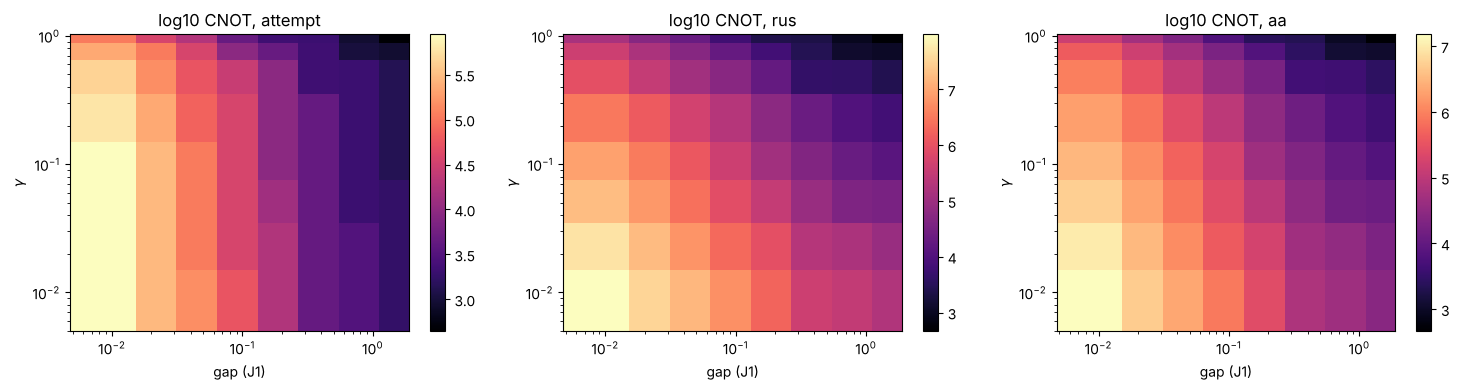

In [5]:
N_MAP     = 8
GAPS_MAP  = np.geomspace(0.01, 1.5, 8)
GAMS_MAP  = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.8, 0.95]
EPS_MAP   = 1e-2

C = {pr: np.full((len(GAPS_MAP), len(GAMS_MAP)), np.nan) for pr in ("attempt",) + fc.PROTOCOLS}
t0 = time.time()
for i, g in enumerate(GAPS_MAP):
    c_ = fc.Chain(N_MAP, fc.delta_for_gap(N_MAP, g, J1=J1, J2=J2), J1, J2)
    rr, _ = fc.measure_point(c_, GAMS_MAP, [EPS_MAP])
    for j, r_ in enumerate(rr):
        C["attempt"][i, j] = r_[EPS_MAP]["rus"]["cnot"]
        for pr in fc.PROTOCOLS:
            C[pr][i, j] = r_[EPS_MAP][pr]["cost"]
print(f"{len(GAPS_MAP)} x {len(GAMS_MAP)} map in {time.time() - t0:.0f} s")

Gm, Ym = np.meshgrid(GAPS_MAP, GAMS_MAP, indexing="ij")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (kind, Ck) in zip(ax, C.items()):
    m = a.pcolormesh(GAPS_MAP, GAMS_MAP, np.log10(Ck).T, shading="nearest", cmap="magma")
    a.set(xscale="log", yscale="log", xlabel="gap (J1)", ylabel=r"$\gamma$", title=f"log10 CNOT, {kind}")
    plt.colorbar(m, ax=a)
    sel = Ym <= 0.95
    X = np.column_stack([np.ones(sel.sum()), -np.log(Gm[sel]), -np.log(Ym[sel])])
    coef = np.linalg.lstsq(X, np.log(Ck[sel]), rcond=None)[0]
    print(f"{kind:8s}: C ~ gap^-{coef[1]:.2f} * gamma^-{coef[2]:.2f}")
plt.tight_layout(); plt.show()

## 5. The saved N = 8–16 results

`results/map_N*.json` and `results/fits.csv` come from `run_maps.py` and `analyze.py`. The cell plots cost
against the gap at a few overlaps, for every N. Change `KIND` and `EPS_SAVED`.

In [6]:
import analyze
maps = analyze.load("results")
print(open("results/fits.csv").read())

KIND, EPS_SAVED = "rus", 1e-2           # attempt | rus | aa ; 1e-2 | 1e-3
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, gam in zip(ax, (0.01, 0.1, 0.9)):
    for N_, c in zip(maps, plt.cm.viridis(np.linspace(0, 0.9, len(maps)))):
        G, Y, Cs = analyze.grid(maps[N_], EPS_SAVED, KIND)
        j = int(np.argmin(abs(np.array(maps[N_]["gammas"]) - gam)))
        a.loglog(G[:, j], Cs[:, j], "o-", ms=3, color=c, label=f"N={N_}")
    a.set(xlabel="gap (J1)", title=f"gamma = {gam}, {KIND}, eps = {EPS_SAVED:g}"); a.grid(alpha=0.3, which="both")
ax[0].set_ylabel("CNOT"); ax[0].legend(); plt.tight_layout(); plt.show()

eps,kind,N,a_gap,se_a,b_gamma,se_b,alpha_N,se_alpha,R2,points
0.01,attempt,8,1.208,0.019,0.236,0.020,,,0.966,147
0.01,attempt,10,1.199,0.018,0.210,0.019,,,0.969,149
0.01,attempt,12,1.179,0.018,0.205,0.019,,,0.968,148
0.01,attempt,14,1.196,0.017,0.207,0.017,,,0.972,149
0.01,attempt,16,1.154,0.018,0.195,0.018,,,0.967,151
0.01,attempt,all,1.187,0.008,0.211,0.008,2.003,0.059,0.970,744
0.01,rus,8,1.269,0.016,1.221,0.017,,,0.987,147
0.01,rus,10,1.261,0.017,1.205,0.018,,,0.985,149
0.01,rus,12,1.242,0.017,1.202,0.017,,,0.986,148
0.01,rus,14,1.260,0.016,1.197,0.017,,,0.987,149
0.01,rus,16,1.212,0.017,1.187,0.017,,,0.986,151
0.01,rus,all,1.249,0.007,1.202,0.008,1.938,0.055,0.986,744
0.01,aa,8,1.246,0.018,0.763,0.019,,,0.978,147
0.01,aa,10,1.229,0.018,0.738,0.019,,,0.976,149
0.01,aa,12,1.205,0.018,0.736,0.018,,,0.977,148
0.01,aa,14,1.224,0.017,0.743,0.017,,,0.980,149
0.01,aa,16,1.185,0.018,0.729,0.019,,,0.975,151
0.01,aa,all,1.218,0.008,0.742,0.008,1.950,0.059,0.978,744
0.001,attempt,8,1.239,0.01